<a href="https://colab.research.google.com/github/duddukuribalacharan777/deep_learning/blob/main/Skill_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       COCO TRAFFIC DATASET EXPLORATION
Total photographs: 10
Total annotation files: 10

TRAFFIC IMAGES PROCESSED: 10

DISPLAYING TRAFFIC PHOTOGRAPHS WITH BOUNDING BOXES


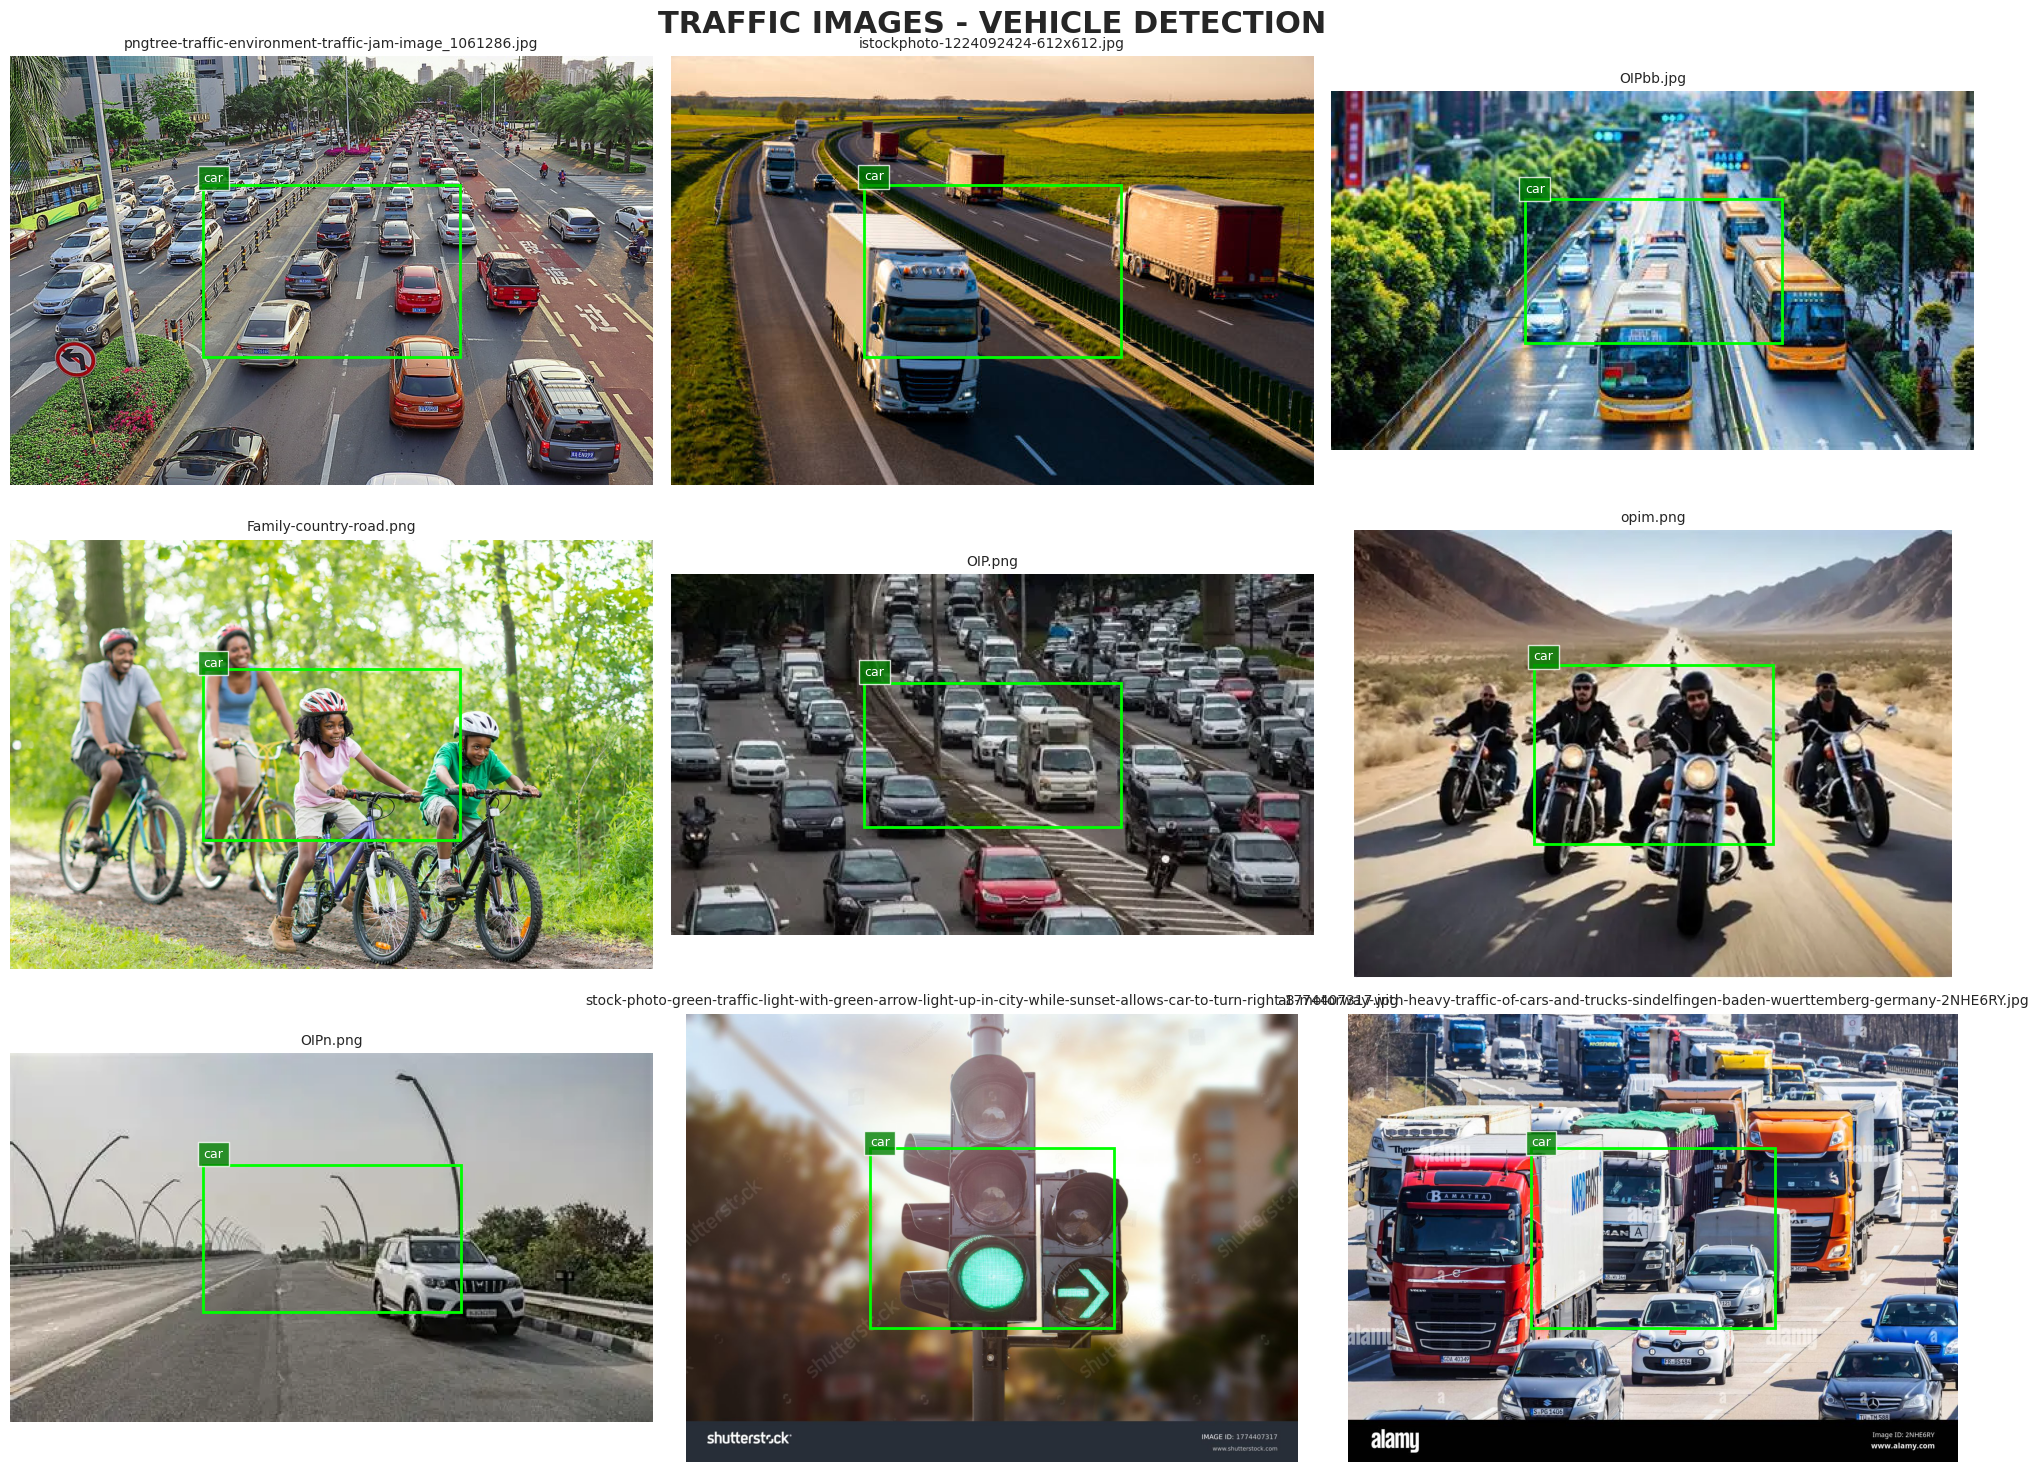

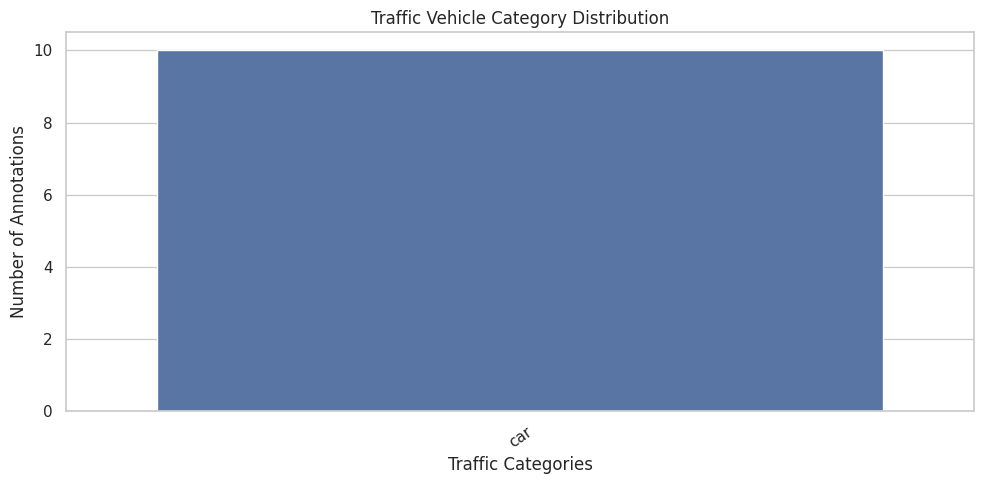

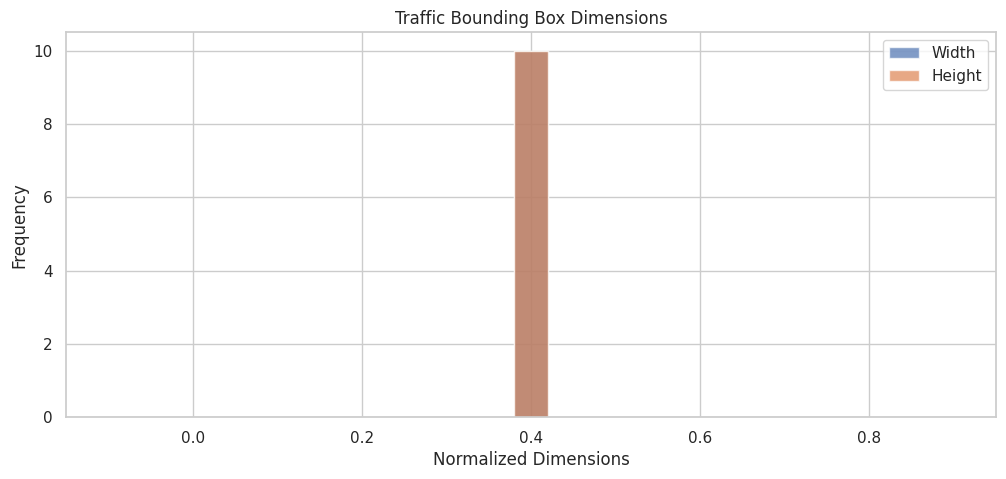


ANNOTATION TABLE


,Image,Category,X Center,Y Center,Width,Height
0,istockphoto-1224092424-612x612.jpg,car,0.5,0.5,0.4,0.4
1,pngtree-traffic-environment-traffic-jam-image_...,car,0.5,0.5,0.4,0.4
2,stock-photo-green-traffic-light-with-green-arr...,car,0.5,0.5,0.4,0.4
3,a8-motorway-with-heavy-traffic-of-cars-and-tru...,car,0.5,0.5,0.4,0.4
4,OIPbb.jpg,car,0.5,0.5,0.4,0.4
5,opim.png,car,0.5,0.5,0.4,0.4
6,OIP.png,car,0.5,0.5,0.4,0.4
7,oipm.png,car,0.5,0.5,0.4,0.4
8,OIPn.png,car,0.5,0.5,0.4,0.4
9,Family-country-road.png,car,0.5,0.5,0.4,0.4



       FINAL TRAFFIC DATASET REPORT
Total Dataset Images : 10
Traffic Images       : 10
Total Annotations    : 10

EXPERIMENT COMPLETED SUCCESSFULLY!


In [7]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image
from collections import Counter
from IPython.display import display

sns.set_theme(style="whitegrid")
random.seed(42)

print("=" * 65)
print("       COCO TRAFFIC DATASET EXPLORATION")
print("=" * 65)

dataset_path = "/content/traffic_coco"

# 1. FIND IMAGE AND LABEL FILES
image_files = []
for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG'):
    image_files.extend(glob.glob(os.path.join(dataset_path, "**", ext), recursive=True))

label_files = glob.glob(
    os.path.join(dataset_path, "**", "labels", "*.txt"),
    recursive=True
) or glob.glob(
    os.path.join(dataset_path, "**", "*.txt"),
    recursive=True
)

if not image_files:
    raise FileNotFoundError("No images found in the dataset folder!")

if not label_files:
    raise FileNotFoundError("No YOLO annotation files found!")

label_lookup = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in label_files
}

print("Total photographs:", len(image_files))
print("Total annotation files:", len(label_files))

# 2. COCO CATEGORY NAMES
class_names = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite",
    "baseball bat", "baseball glove", "skateboard",
    "surfboard", "tennis racket", "bottle", "wine glass",
    "cup", "fork", "knife", "spoon", "bowl", "banana",
    "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair", "couch",
    "potted plant", "bed", "dining table", "toilet", "tv",
    "laptop", "mouse", "remote", "keyboard", "cell phone",
    "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush"
]

# 3. SELECT TRAFFIC OBJECTS
vehicle_ids = [1, 2, 3, 5, 7]
road_ids = [9, 11, 12]

traffic_records = []
category_counts = Counter()

for image_path in image_files:
    name = os.path.splitext(os.path.basename(image_path))[0]
    label_path = label_lookup.get(name)

    if not label_path:
        continue

    objects = []
    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        values = list(map(float, line.split()))
        if len(values) < 5:
            continue

        cid = int(values[0])
        if cid not in vehicle_ids + road_ids:
            continue

        xc, yc, w, h = values[1:5]
        obj = {
            "id": cid,
            "name": class_names[cid],
            "xc": xc,
            "yc": yc,
            "w": w,
            "h": h
        }
        objects.append(obj)

    traffic_records.append({
        "path": image_path,
        "objects": objects
    })
    for obj in objects:
        category_counts[obj["name"]] += 1

print("\nTRAFFIC IMAGES PROCESSED:", len(traffic_records))

# 4. DISPLAY PHOTOGRAPHS WITH BOUNDING BOXES
print("\nDISPLAYING TRAFFIC PHOTOGRAPHS WITH BOUNDING BOXES")

sample = random.sample(
    traffic_records,
    min(9, len(traffic_records))
)

# Dynamic layout
cols = 3
rows = (len(sample) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(20, 5 * rows))
axes = axes.flatten() if len(sample) > 1 else [axes]

for ax, record in zip(axes, sample):
    try:
        img = Image.open(record["path"]).convert("RGB")
        width, height = img.size
        ax.imshow(img)

        for obj in record["objects"]:
            xc = obj["xc"] * width
            yc = obj["yc"] * height
            bw = obj["w"] * width
            bh = obj["h"] * height

            x = xc - bw / 2
            y = yc - bh / 2

            rectangle = patches.Rectangle(
                (x, y),
                bw,
                bh,
                linewidth=2,
                edgecolor="lime",
                facecolor="none"
            )
            ax.add_patch(rectangle)
            ax.text(
                x,
                max(0, y - 5),
                obj["name"],
                color="white",
                fontsize=9,
                bbox=dict(facecolor="green", alpha=0.8)
            )
        ax.set_title(os.path.basename(record["path"]), fontsize=10)
    except Exception as e:
        ax.text(0.5, 0.5, f"Error displaying\n{os.path.basename(record['path'])}", ha='center', va='center')
    ax.axis("off")

for ax in axes[len(sample):]:
    ax.axis("off")

plt.suptitle(
    "TRAFFIC IMAGES - VEHICLE DETECTION",
    fontsize=22,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

# 5. CATEGORY DISTRIBUTION
names = list(category_counts.keys())
counts = list(category_counts.values())

if names:
    plt.figure(figsize=(10, 5))
    sns.barplot(x=names, y=counts)
    plt.title("Traffic Vehicle Category Distribution")
    plt.xlabel("Traffic Categories")
    plt.ylabel("Number of Annotations")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

# 6. BOUNDING BOX ANALYSIS
widths = [obj["w"] for r in traffic_records for obj in r["objects"]]
heights = [obj["h"] for r in traffic_records for obj in r["objects"]]

if widths:
    plt.figure(figsize=(12, 5))
    plt.hist(widths, bins=25, alpha=0.7, label="Width")
    plt.hist(heights, bins=25, alpha=0.7, label="Height")
    plt.title("Traffic Bounding Box Dimensions")
    plt.xlabel("Normalized Dimensions")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

# 7. ANNOTATION TABLE
rows_list = []
for record in traffic_records:
    for obj in record["objects"]:
        rows_list.append({
            "Image": os.path.basename(record["path"]),
            "Category": obj["name"],
            "X Center": round(obj["xc"], 4),
            "Y Center": round(obj["yc"], 4),
            "Width": round(obj["w"], 4),
            "Height": round(obj["h"], 4)
        })

if rows_list:
    df = pd.DataFrame(rows_list)
    print("\nANNOTATION TABLE")
    display(df.head(20))

# 8. FINAL REPORT
print("\n" + "=" * 60)
print("       FINAL TRAFFIC DATASET REPORT")
print("=" * 60)
print("Total Dataset Images :", len(image_files))
print("Traffic Images       :", len(traffic_records))
print("Total Annotations    :", len(rows_list))
print("\nEXPERIMENT COMPLETED SUCCESSFULLY!")
print("=" * 60)